# Some Visualizations for EDA

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Scatter Plot

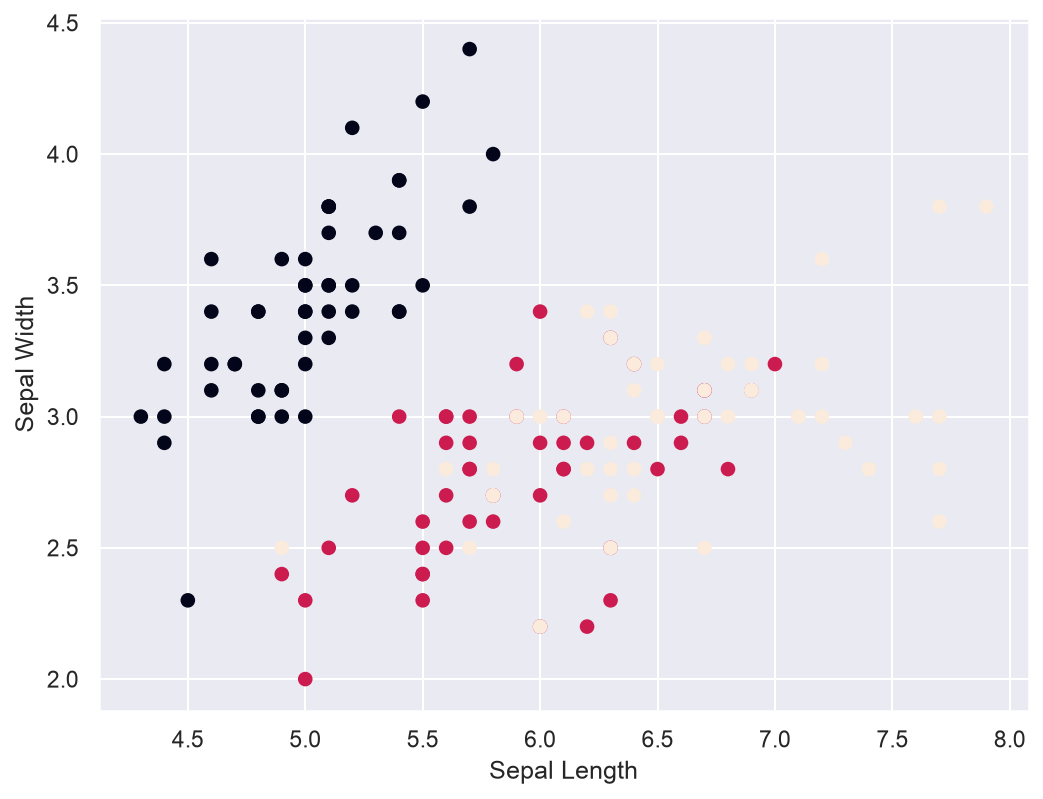

In [2]:
# default parametes of matplotlib
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['figure.dpi'] = 150

sns.set() 

#Load Dataset
df = sns.load_dataset('iris')

df['species'] =  df['species'].map({'setosa': 0, "versicolor": 1, "virginica": 2})

# A regular scatter plot
plt.scatter(x=df["sepal_length"], y=df["sepal_width"], c = df.species)

# Create labels for axises
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')

# Display the plot on the screen
plt.show()

Scatter plot with Axis Sepal Length and Width

### Bubble Chart

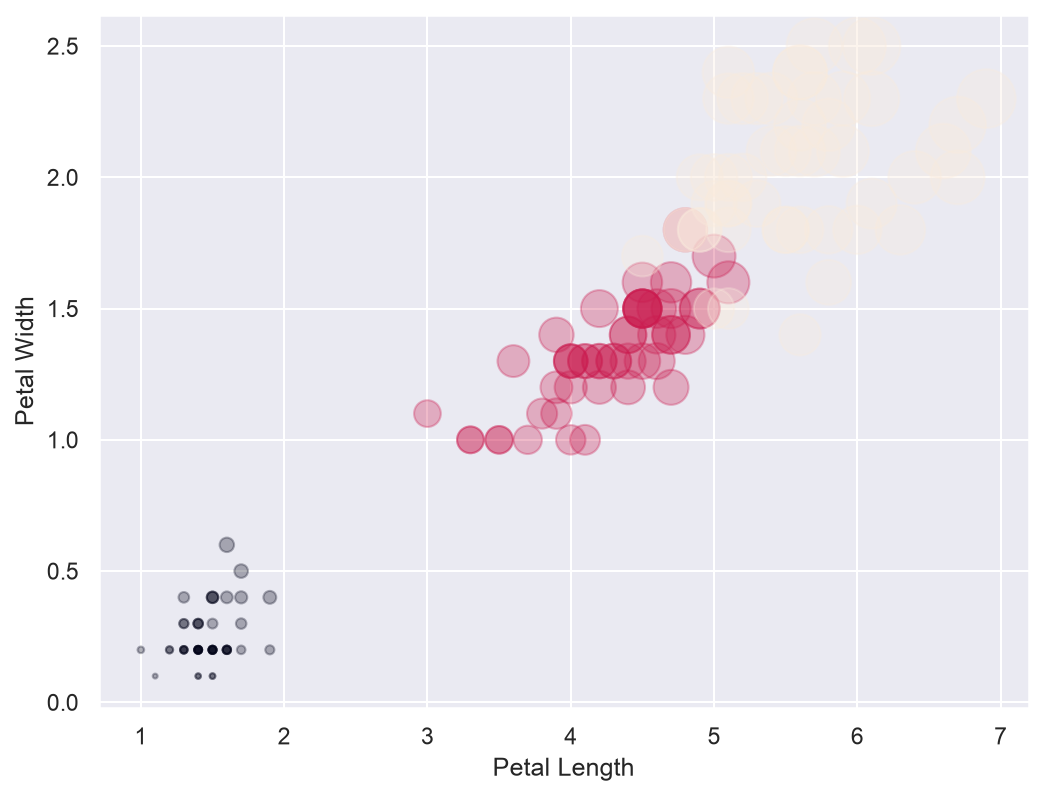

In [4]:
# Load the Iris dataset
df = sns.load_dataset('iris')

df['species'] =  df['species'].map({'setosa': 0, "versicolor": 1, "virginica": 2})

# Bubble plot
plt.scatter(df.petal_length, df.petal_width,
            s=50*df.petal_length*df.petal_width, 
            c=df.species,
            alpha=0.3
            )

# Labels for axises
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.show()

### Scatter plot using seaborn

<Axes: xlabel='sepal_length', ylabel='sepal_width'>

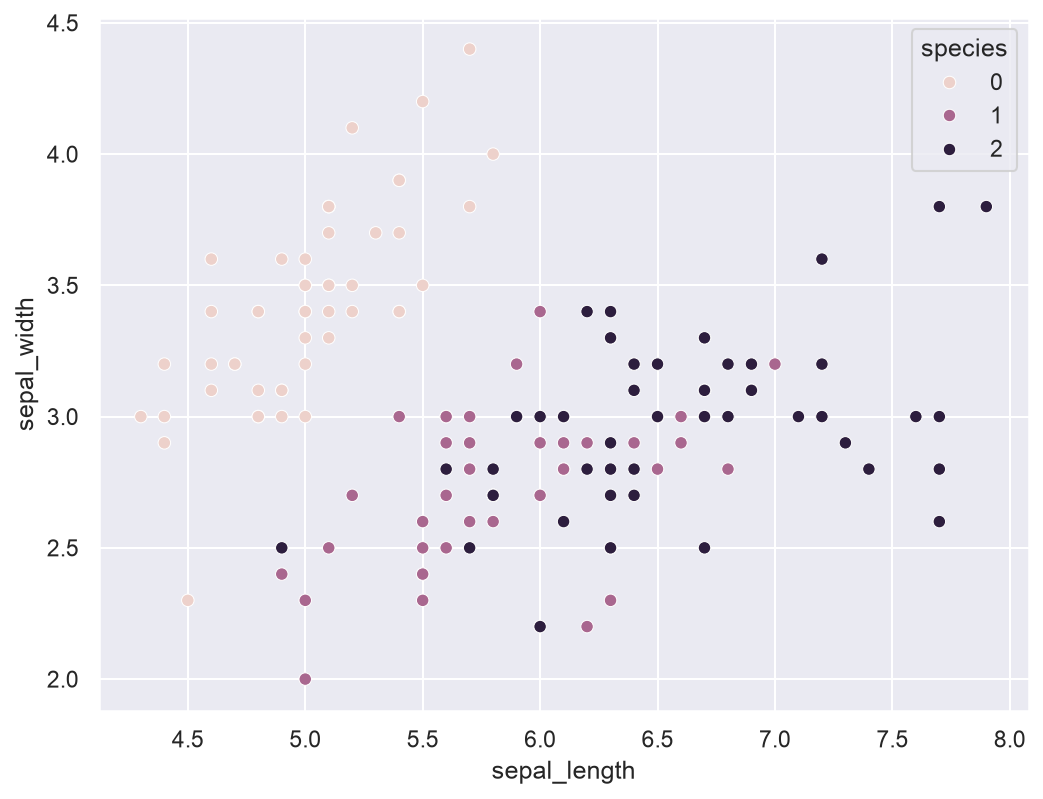

In [5]:
df = sns.load_dataset('iris')

df['species'] =  df['species'].map({'setosa': 0, "versicolor": 1, "virginica": 2})
sns.scatterplot(x=df["sepal_length"], y=df["sepal_width"], hue=df.species, data=df)


Seaborn Scatter plot is a lot more detailed

## Table Chart

In [4]:
# Years under consideration
years = ["2010", "2011", "2012", "2013", "2014"]

# Available watt
columns = ['4.5W', '6.0W', '7.0W','8.5W','9.5W','13.5W','15W']
unitsSold = [
             [65, 141, 88, 111, 104, 71, 99],
             [85, 142, 89, 112, 103, 73, 98],
             [75, 143, 90, 113, 89, 75, 93],
             [65, 144, 91, 114, 90, 77, 92],
             [55, 145, 92, 115, 88, 79, 93],
            ]

# Define the range and scale for the y axis
values = np.arange(0, 600, 100)

In [ ]:
# preparation for data set is done. Now creating table.

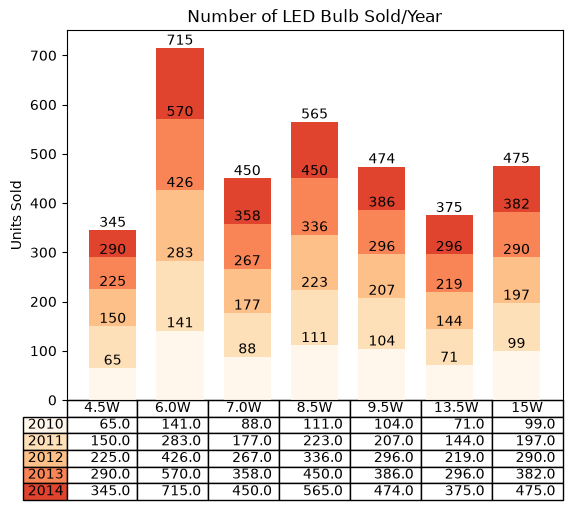

In [10]:
colors = plt.cm.OrRd(np.linspace(0, 0.7, len(years)))
index = np.arange(len(columns)) + 0.3
bar_width = 0.7

y_offset = np.zeros(len(columns))
fig, ax = plt.subplots()

cell_text = []

n_rows = len(unitsSold)
for row in range(n_rows):
    plot = plt.bar(index, unitsSold[row], bar_width, bottom=y_offset, 
                   color=colors[row])
    y_offset = y_offset + unitsSold[row]
    cell_text.append(['%1.1f' % (x) for x in y_offset])
    i=0
# Each iteration of this for loop, labels each bar with corresponding value for the given year
    for rect in plot:
        height = rect.get_height()
        ax.text(rect.get_x() + rect.get_width()/2, y_offset[i],'%d' 
                % int(y_offset[i]), 
                ha='center', va='bottom')
        i = i+1 
        
# Add a table to the bottom of the axes
the_table = plt.table(cellText=cell_text, rowLabels=years, 
                rowColours=colors, colLabels=columns, loc='bottom')
plt.ylabel("Units Sold")
plt.xticks([])
plt.title('Number of LED Bulb Sold/Year')
plt.show()


In [ ]:
# we have created an easily intepretable table chart.

### Lolipop Chart

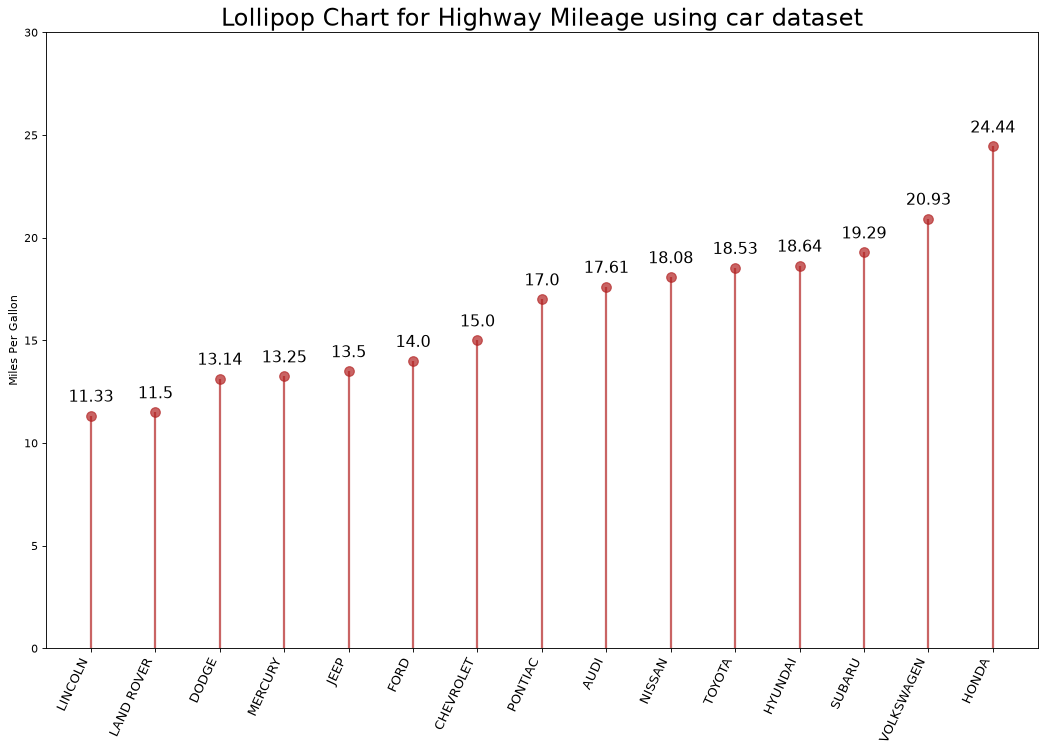

In [14]:
# 1. Read the dataset:
carDF = pd.read_csv('https://raw.githubusercontent.com/PacktPublishing/hands-on-exploratory-data-analysis-with-python/master/Chapter%202/cardata.csv')

# 2. Group by manufacturer and take average milage:
processedDF = carDF[['cty','manufacturer']].groupby('manufacturer').apply(lambda x: x.mean())

# 3. Sort the values by cty and reset index:
processedDF.sort_values('cty', inplace=True)
processedDF.reset_index(inplace=True)

# 4. Plot the graph:
fig, ax = plt.subplots(figsize=(16,10), dpi= 80)
ax.vlines(x=processedDF.index, ymin=0, ymax=processedDF.cty, color='firebrick', alpha=0.7, linewidth=2)
ax.scatter(x=processedDF.index, y=processedDF.cty, s=75, color='firebrick', alpha=0.7)

# 5. Annotate the Title:
ax.set_title('Lollipop Chart for Highway Mileage using car dataset', fontdict={'size':22})

# 6. Anotate labels, xticks, and ylims:
ax.set_ylabel('Miles Per Gallon')
ax.set_xticks(processedDF.index)
ax.set_xticklabels(processedDF.manufacturer.str.upper(), rotation=65, fontdict={'horizontalalignment': 'right', 'size':12})
ax.set_ylim(0, 30)

# 7. Write the actual values in the plot:
for row in processedDF.itertuples():
    ax.text(row.Index, row.cty+.5, s=round(row.cty, 2), horizontalalignment= 'center', verticalalignment='bottom', fontsize=14)

# 8. Display plot
plt.show()
     